# Fitting one window end-to-end

Uses the SPARTA TODCOR engine on a single realistic window: build a noisy composite at a known
`(v1, v2, a1, a2)`, prepare the window with `prepare_window`, recover the composite with
`todcor_map`, overlay the best-fit spectrum, and validate the Cramér–Rao velocity errors
(`crlb_from_map`) against a Monte Carlo. The method behind every step is derived in
`01_method`; the full spec is [`todcor_method.md`](../../../packages/todcor/docs/todcor_method.md).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT primitives
# (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# The SPARTA figure style: data black steps, models red, one extra series
# blue, maps as grey-scale images with the peak black.
from sparta.plotting import (GREY, apply_style, DLNL_LABEL, map_colorbar, map_image,
                             mark_fit, mark_truth, plot_data, plot_extra, plot_model)
apply_style()

# Speed of light, km/s
C = tf.C_KMS
# One Gaussian absorption or emission line: the building block of the templates
def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

# Synthetic rest-frame templates, finely sampled (0.5 km/s) and wider than the window:
# an OB-like absorber (primary) and a broad WR-like emitter (secondary)
wave_t, _ = tf.log_lambda_grid(4560.0, 4760.0, 0.5)
tmpl1 = (wave_t, gauss_line(wave_t, 4634., 0.25, 120.) * gauss_line(wave_t, 4686., 0.15, 120.))
tmpl2 = (wave_t, gauss_line(wave_t, 4686., 0.60, 400., emission=True))

# The observed window: a uniform log-lambda grid (constant velocity step dv, km/s)
dv = 3.0
wave, u = tf.log_lambda_grid(4600.0, 4720.0, dv)
print(f"window N={len(wave)} pixels, dv={dv} km/s; templates {wave_t[0]:.0f}-{wave_t[-1]:.0f} Å")

window N=2574 pixels, dv=3.0 km/s; templates 4560-4760 Å


## 1. Build a composite

`composite_flux` shifts each template by physical resampling and adds them in residual space.
We inject a primary at `v1 = +80` and a secondary at `v2 = −160` km/s (light fractions
`a1 = 0.70`, `a2 = 0.55`) and add white noise:

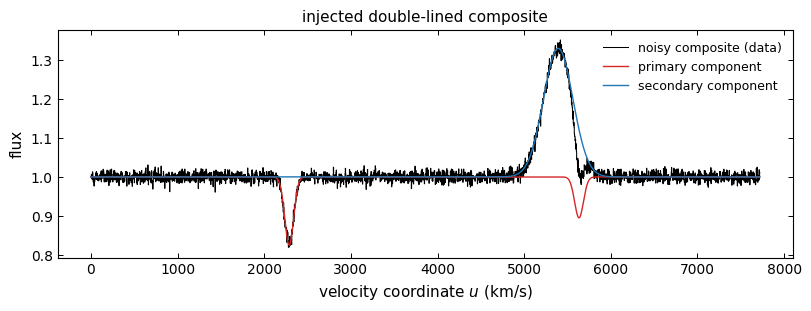

In [2]:
# Truth: velocities (km/s) and light fractions of the two components
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.70, 0.55
sigma = 0.01
# Noiseless composite: shift, scale and add the templates
comp = tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t])
# Add white noise to make the data
rng = np.random.default_rng(0)
data = comp + rng.normal(0, sigma, len(comp))

# Plot the noisy data with the two injected components
fig, ax = plt.subplots(figsize=(8, 3.0))
plot_data(ax, u, data, label="noisy composite (data)")
plot_model(ax, u, tf.composite_flux(wave, [tmpl1], [v1t], [a1t]), lw=1, label="primary component")
plot_extra(ax, u, tf.composite_flux(wave, [tmpl2], [v2t], [a2t]), label="secondary component")
ax.set_xlabel("velocity coordinate $u$ (km/s)"); ax.set_ylabel("flux")
ax.set_title("injected double-lined composite"); ax.legend()
plt.show()

## 2. The TODCOR map

`prepare_window` keeps the observed pixels and puts both templates on the window's grid extended
by the largest trial velocity, `v_max`, so no shift wraps around into the window (`01_method`
§2). `todcor_map` = `profile_from_stats(window_stats(...))`: it forms the six sufficient
statistics over the window's pixels (with a free offset profiled out), solves the 2×2 amplitude
problem at every `(v1, v2)`, and returns the profile log-likelihood surface. The peak is the
joint velocity estimate:

2574 of 2574 pixels kept; templates extended by 155 pixels per side
truth : v1=+80.0  v2=-160.0  a1=0.70  a2=0.55
fit   : v1=+81.0  v2=-160.0  a1=0.70  a2=0.55


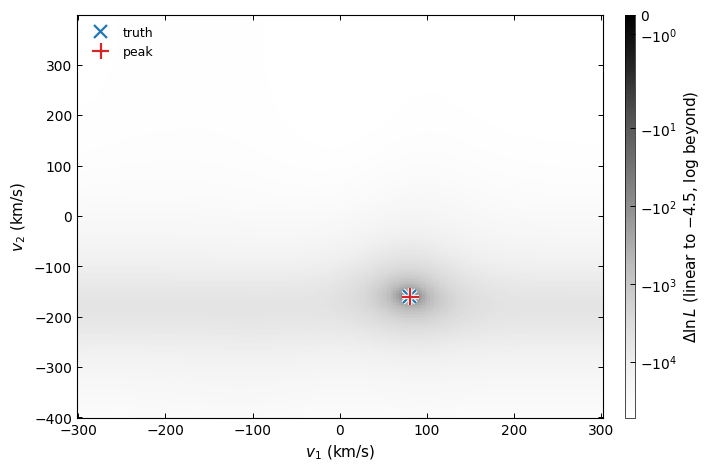

In [3]:
# Trial velocity grids (km/s)
v1g = np.arange(-300, 301, 3.0)
v2g = np.arange(-400, 401, 3.0)
# Prepare the window: the observed pixels, the templates extended by the largest trial velocity
win = tf.prepare_window(wave, data, *tmpl1, *tmpl2, v_max=400.0)
# The TODCOR map: profile log-likelihood at every (v1, v2) (todcor_map)
res = tf.todcor_map(win.data_g, win.g1, win.g2, win.dv, v1g, v2g, sigma=sigma)
# The peak of the map is the joint estimate
b = res["best"]
# Compare the fitted peak with the injected values
print(f"{win.wave.size} of {wave.size} pixels kept; templates extended by {win.extension} pixels per side")
print(f"truth : v1={v1t:+.1f}  v2={v2t:+.1f}  a1={a1t:.2f}  a2={a2t:.2f}")
print(f"fit   : v1={b['v1']:+.1f}  v2={b['v2']:+.1f}  a1={b['a1']:.2f}  a2={b['a2']:.2f}")

# Plot the map (peak black) with the truth and the fitted peak
fig, ax = plt.subplots(figsize=(7.0, 4.6))
logl = res["logL_profile"].T                 # the map is [v1, v2]; v1 along x
mesh = map_image(ax, v1g, v2g, logl, loglike=True)   # Delta lnL, peak black
map_colorbar(mesh, DLNL_LABEL)
mark_truth(ax, v1t, v2t, label="truth")
mark_fit(ax, b["v1"], b["v2"], label="peak")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.legend(loc="upper left")
plt.show()

## 3. Best fit and reconstruction

`model_flux` rebuilds the composite from the fitted `(v1, v2, a1, a2)` with the *same* model as
the fit, the extended templates shifted by the Fourier phase factor and read on the window; the
window's offset is the mean of data minus model. So the residual is an honest check:

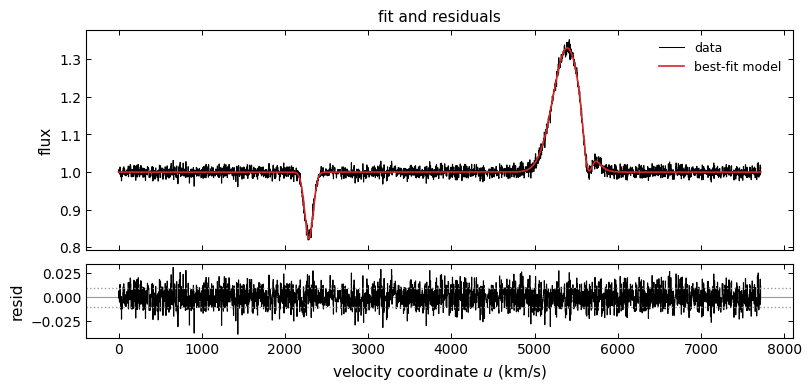

residual RMS = 0.0100   (injected sigma = 0.01)


In [4]:
# Rebuild the best-fit spectrum with the model used in the fit
model = tf.model_flux(win.g1, win.g2, win.wave.size, win.dv, b["v1"], b["v2"], b["a1"], b["a2"])
offset = np.mean(win.data_g - model)                      # the fitted offset of the window
resid = win.data_g - model - offset
# Back on the flux scale: prepare_window removed the data's median
fit_flux = model + offset + (data - win.data_g)

# Top: data and best-fit model; bottom: residuals with the +-sigma noise level
fig, (a0, a1_) = plt.subplots(2, 1, figsize=(8, 3.8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
plot_data(a0, u, data, label="data")
plot_model(a0, u, fit_flux, label="best-fit model")
a0.set_ylabel("flux"); a0.legend(); a0.set_title("fit and residuals")
a1_.axhline(0, color=GREY, lw=0.8)
plot_data(a1_, u, resid)
a1_.axhline(sigma, ls=":", color=GREY); a1_.axhline(-sigma, ls=":", color=GREY)
a1_.set_xlabel("velocity coordinate $u$ (km/s)"); a1_.set_ylabel("resid")
plt.show()
# The residual RMS should match the injected noise
print(f"residual RMS = {np.std(resid):.4f}   (injected sigma = {sigma})")

## 4. Cramér–Rao velocity errors

`crlb_from_map` fits a degree-6 2-D polynomial to the log-likelihood over ±4 nodes around its
peak; the polynomial's maximum is the sub-grid peak, and its negative Hessian there is the
Fisher information, whose inverse is the `(v1, v2)` covariance. Because the map is already
*profiled* over the amplitudes (and the offset), this is the full CRLB. Here the 3 km/s grid
resolves the peak (the lines are 120 km/s wide); on narrow lines, evaluate a fine map around the
coarse peak first (`refine_grid`, as `CCF2d` does;
[correlation engines § peak refinement](../../../docs/correlation_engines.md#peak-refinement-and-the-errors)):

In [5]:
# A degree-6 polynomial fit to the map peak gives the refined peak and the errors (km/s)
cr = tf.crlb_from_map(res["logL_profile"], v1g, v2g)
# Report errors, correlation, and the peak before and after sub-grid refinement
print(f"sigma_v1 = {cr['sigma_v1']:.2f} km/s     sigma_v2 = {cr['sigma_v2']:.2f} km/s")
print(f"correlation rho(v1,v2) = {cr['rho']:+.2f}")
print(f"grid peak      : v1={cr['peak'][0]:+.1f}  v2={cr['peak'][1]:+.1f}")
print(f"sub-grid peak  : v1={cr['peak_refined'][0]:+.2f}  v2={cr['peak_refined'][1]:+.2f}")
print(f"truth          : v1={v1t:+.1f}  v2={v2t:+.1f}")

sigma_v1 = 0.65 km/s     sigma_v2 = 0.76 km/s
correlation rho(v1,v2) = -0.08
grid peak      : v1=+81.0  v2=-160.0
sub-grid peak  : v1=+80.26  v2=-159.45
truth          : v1=+80.0  v2=-160.0


## 5. CRLB vs Monte Carlo

The honest test of the error bars: refit many independent noise realisations, take each one's
sub-grid peak, and compare their scatter with the CRLB 1σ ellipse. We use a focused velocity
grid around the peak for speed:

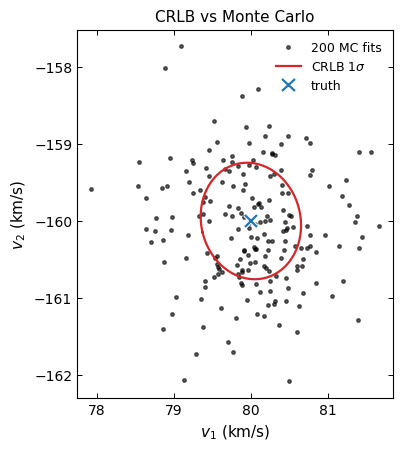

MC scatter : sd_v1=0.665  sd_v2=0.748 km/s  (MC/CRLB = 1.02, 0.99; ±0.05 from 200 draws)
CRLB       : sig_v1=0.653  sig_v2=0.758 km/s
MC mean - truth: -0.001, -0.087 km/s (±0.047, ±0.053)


In [6]:
v1f = np.arange(20, 141, 3.0)      # focused grid around the truth (fast)
v2f = np.arange(-220, -99, 3.0)
# Refit many independent noise realisations on the focused grid; the window's pixels and
# templates do not change, and any constant level of the data is taken by the fitted offset
assert win.wave.size == wave.size                         # no pixel was dropped
n_mc = 200
mc = np.empty((n_mc, 2))
rng_mc = np.random.default_rng(1)
for m in range(n_mc):
    d = comp + rng_mc.normal(0, sigma, len(comp))
    r = tf.todcor_map(d, win.g1, win.g2, win.dv, v1f, v2f, sigma=sigma)
    mc[m] = tf.crlb_from_map(r["logL_profile"], v1f, v2f)["peak_refined"]

# CRLB ellipse from the covariance at the fiducial fit
th = np.linspace(0, 2*np.pi, 200)
vals, vecs = np.linalg.eigh(cr["cov"])
ell = (vecs @ (np.sqrt(vals)[:, None] * np.vstack([np.cos(th), np.sin(th)])))

# Plot the Monte Carlo fits against the CRLB 1-sigma ellipse around the truth
fig, ax = plt.subplots(figsize=(5.0, 4.4))
ax.plot(mc[:, 0], mc[:, 1], "o", color="k", ms=2.5, alpha=0.6, label=f"{n_mc} MC fits")
plot_model(ax, v1t + ell[0], v2t + ell[1], lw=1.6, label="CRLB 1$\\sigma$")
mark_truth(ax, v1t, v2t, label="truth")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.set_title("CRLB vs Monte Carlo"); ax.legend(); ax.set_aspect("equal")
plt.show()
# The scatter of the fits should match the CRLB, and their mean the truth
sd = mc.std(axis=0)
print(f"MC scatter : sd_v1={sd[0]:.3f}  sd_v2={sd[1]:.3f} km/s  (MC/CRLB = {sd[0] / cr['sigma_v1']:.2f}, "
      f"{sd[1] / cr['sigma_v2']:.2f}; ±{1 / np.sqrt(2 * n_mc):.2f} from {n_mc} draws)")
print(f"CRLB       : sig_v1={cr['sigma_v1']:.3f}  sig_v2={cr['sigma_v2']:.3f} km/s")
print(f"MC mean - truth: {mc[:, 0].mean() - v1t:+.3f}, {mc[:, 1].mean() - v2t:+.3f} km/s "
      f"(±{sd[0] / np.sqrt(n_mc):.3f}, ±{sd[1] / np.sqrt(n_mc):.3f})")

## Summary

One window, start to finish: `composite_flux` → `prepare_window` → `todcor_map` → read the
peak → `model_flux` reconstruction → `crlb_from_map` errors, with the CRLB matching the
Monte-Carlo scatter. Remember the CRLB is *local* and its absolute scale assumes the input
`sigma` is right (rescale by `√χ²ᵥ` otherwise; see
[correlation engines § noise](../../../docs/correlation_engines.md#noise-oversampling-and-n_eff)).

Next: **`03_multiwindow_combination`**: combine several line windows of one epoch by *adding*
their sufficient statistics, and watch a single-window degeneracy disappear.